# DB-scan 


In [195]:
import profile
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import sys
import os
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score,davies_bouldin_score

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

from src.utils import data_understanding as du
from src.utils import utils as ut
profile_df = pd.read_csv("../../data/processed/patient_profile.csv")

profile_df.drop_duplicates(inplace=True)


profile_df

,subject_id,ACS_acute_ischemic,Chronic_ischemic,Heart_failure,Valvular_nonrheumatic,Myocarditis_or_cardiomyopathy,Pericardial_disease,Endocarditis,Cardiac_arrest,Arrhythmias_or_conduction,...,max_ptt,max_inr(pt),max_hemoglobin,max_wbc count,max_platelet count,max_white blood cells,abnormal_lab_event_ratio,resistant_microorganism_ratio,intermediate_microorganism_ratio,sensitive_microorganism_ratio
0,10000980,1,0,1,0,0,0,0,0,0,...,5.286957,2.0,-0.475000,0.0,0.251724,0.328571,0.410714,0.0,0.0,0.0
1,10002013,1,0,0,0,0,0,0,0,0,...,4.634783,0.5,0.025000,0.0,0.389655,0.714286,0.375000,0.0,0.0,0.0
2,10002155,1,0,0,0,0,0,0,0,0,...,5.661538,10.5,0.125000,0.0,0.341379,0.500000,0.384058,0.0,0.0,0.0
3,10004457,0,0,0,1,0,0,0,0,0,...,0.000000,0.0,-0.075000,0.0,0.396552,0.357143,0.300000,0.0,0.0,0.0
4,10007058,1,0,0,0,0,0,0,0,0,...,4.582609,1.5,-0.315789,0.0,0.220000,1.416667,0.375000,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4378,19998596,0,0,0,0,0,0,0,0,1,...,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
4379,19998597,0,0,0,0,0,1,0,0,0,...,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
4380,19998598,0,0,0,0,0,0,0,0,1,...,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
4381,19998599,0,0,0,0,0,1,0,0,0,...,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0


In [196]:
profile_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4383 entries, 0 to 4382
Data columns (total 37 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   subject_id                        4383 non-null   int64  
 1   ACS_acute_ischemic                4383 non-null   int64  
 2   Chronic_ischemic                  4383 non-null   int64  
 3   Heart_failure                     4383 non-null   int64  
 4   Valvular_nonrheumatic             4383 non-null   int64  
 5   Myocarditis_or_cardiomyopathy     4383 non-null   int64  
 6   Pericardial_disease               4383 non-null   int64  
 7   Endocarditis                      4383 non-null   int64  
 8   Cardiac_arrest                    4383 non-null   int64  
 9   Arrhythmias_or_conduction         4383 non-null   int64  
 10  number_of_hadm                    4383 non-null   int64  
 11  gender                            4383 non-null   int64  
 12  age   

In [197]:
#correletion
profile_df['subject_id'] = profile_df['subject_id'].astype(str)
# Seleziona solo le colonne numeriche dal profilo paziente
numeric_cols = profile_df.select_dtypes(include='number').columns
profile_num= profile_df[numeric_cols]

#print the feautures with correlation higer than 0.8
corr_matrix = profile_num.corr().abs()
high_corr_var=np.where(corr_matrix>0.8)
high_corr_var=[(corr_matrix.columns[x],corr_matrix.columns[y]) for x,y in zip(*high_corr_var) if x!=y and x<y]
high_corr_var

[('unique_antibiotics_count', 'sensitive_microorganism_ratio')]

## some consideration
### sensitve_micro_ratio and unique-antibioti_count have a correlation>0.8 , for our analysis sensitve_micro_ratio is more signficant, I drop the other


In [198]:
# Drop highly correlated features
profile_df = profile_df.drop(columns=['unique_antibiotics_count'])
profile_df=profile_df.drop(columns=['max_wbc count'])

# Identifica colonne categoriche da escludere
categorical_cols = ['subject_id', 'gender', 'ACS_acute_ischemic', 'Chronic_ischemic', 
                   'Heart_failure', 'Valvular_nonrheumatic', 'Myocarditis_or_cardiomyopathy', 
                   'Pericardial_disease', 'Endocarditis', 'Cardiac_arrest', 
                   'Arrhythmias_or_conduction']

# Seleziona solo le colonne numeriche per il clustering
numeric_cols = [col for col in profile_df.columns if col not in categorical_cols]

# Verifica le colonne numeriche selezionate
print("Colonne numeriche per clustering:")
print(numeric_cols)
print(f"\nNumero di features: {len(numeric_cols)}")

Colonne numeriche per clustering:
['number_of_hadm', 'age', 'lab_event_count', 'microbio_test_count', 'unique_microorganisms_count', 'unique_procedures_count', 'max_glucose', 'max_potassium', 'max_sodium', 'max_creatinine', 'max_bicarbonate', 'max_calcium, total', 'max_urea nitrogen', 'max_troponin t', 'max_ntprobnp', 'max_ptt', 'max_inr(pt)', 'max_hemoglobin', 'max_platelet count', 'max_white blood cells', 'abnormal_lab_event_ratio', 'resistant_microorganism_ratio', 'intermediate_microorganism_ratio', 'sensitive_microorganism_ratio']

Numero di features: 24


In [199]:
skewed = [
    'number_of_hadm',
    'lab_event_count',
    'microbio_test_count',
    'unique_microorganisms_count',
    'unique_procedures_count',
    'max_troponin t',
    'max_ntprobnp',
    'max_urea nitrogen'
]

profile_df[numeric_cols][skewed] = np.log1p(profile_df[numeric_cols][skewed])

#use the standard scaler to scale the data
x = StandardScaler()
X = x.fit_transform(profile_df[numeric_cols])



C:\Users\Cominotti\AppData\Local\Temp\ipykernel_21568\3851107606.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  profile_df[numeric_cols][skewed] = np.log1p(profile_df[numeric_cols][skewed])


In [200]:
#compute pairwise distance and distance matrix
dist = pdist(X, 'euclidean') #pair wise distance
print (dist)
dist = squareform(dist) #distance matrix given the vector dist
print()
print(dist)

[6.12286065 5.05418351 6.17371514 ... 1.05932826 1.48305957 2.54238783]

[[0.         6.12286065 5.05418351 ... 7.23321676 7.40190602 7.25490414]
 [6.12286065 0.         6.43328152 ... 5.2648407  5.37035604 5.46973613]
 [5.05418351 6.43328152 0.         ... 7.42370335 7.49890311 7.57039214]
 ...
 [7.23321676 5.2648407  7.42370335 ... 0.         1.05932826 1.48305957]
 [7.40190602 5.37035604 7.49890311 ... 1.05932826 0.         2.54238783]
 [7.25490414 5.46973613 7.57039214 ... 1.48305957 2.54238783 0.        ]]


## strategia 
### dopo varie prove  vedendo che già con k bassi il numero di cluster è basso , partiamo da k=4

In [201]:
k = 4
kth_distances = list()
for d in dist:
    index_kth_distance = np.argsort(d)[k]
    kth_distances.append(d[index_kth_distance])

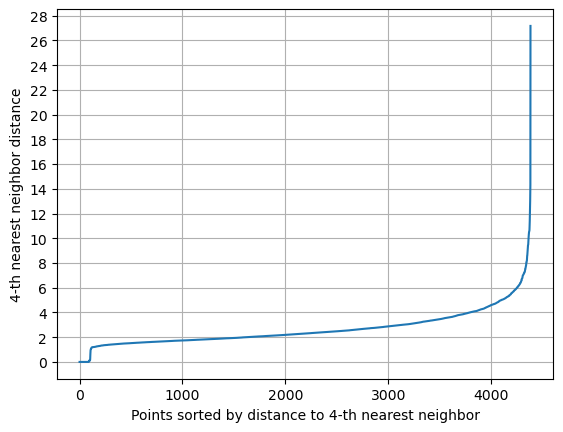

In [202]:
#plot the sorted kth distances with grid 
kth_distances = np.array(kth_distances)
kth_distances = np.sort(kth_distances)
plt.plot(kth_distances)
plt.xlabel('Points sorted by distance to {}-th nearest neighbor'.format(k))
plt.ylabel('{}-th nearest neighbor distance'.format(k))
plt.locator_params(axis='y', nbins=15)  # Aumenta numero di tick sull'asse y
plt.grid()
plt.show()

### dopo varie prove eps=5 da la migliore metrica  e maggiore numero di cluster quindi scegliamo quella al momento
### la ricerca del min sample è limitata a 50, perche dopo varie provo abbiamo osservato che per numeri piu elevati la silhuette peggiorava o rimaneve pressoche costante e il numero di cluster rimaneva costante a 3

In [203]:
# Funzione aggiornata per calcolare solo il Silhouette Score
epsList = [ 5]
best_ms, best_eps, best_silhouette = 0, 0, -1.0

for min_samples in range(4, 80):
    for eps in epsList:
        dbscan = DBSCAN(eps=eps, min_samples=min_samples)
        dbscan.fit(X)
        
        # Ottieni i cluster generati
        unique_labels, counts = np.unique(dbscan.labels_, return_counts=True)
        clusters = len(unique_labels)
        
        # Verifica il numero di cluster (escludendo noise se presente)
        if clusters > 1:
            silhouette = silhouette_score(X, dbscan.labels_)
            print(f'min_samples: {min_samples}, eps: {eps}, Clusters: {clusters}, Silhouette Score: {silhouette:.4f}')
            
            # Aggiorna il miglior punteggio se necessario
            if silhouette > best_silhouette:
                best_silhouette = silhouette
                best_ms = min_samples
                best_eps = eps

print(f'\nBest min_samples: {best_ms}, Best eps: {best_eps}, Best Silhouette Score: {best_silhouette:.4f}')

min_samples: 4, eps: 5, Clusters: 4, Silhouette Score: 0.4640
min_samples: 5, eps: 5, Clusters: 4, Silhouette Score: 0.4618
min_samples: 6, eps: 5, Clusters: 5, Silhouette Score: 0.3767
min_samples: 7, eps: 5, Clusters: 5, Silhouette Score: 0.3855
min_samples: 8, eps: 5, Clusters: 5, Silhouette Score: 0.3860
min_samples: 9, eps: 5, Clusters: 3, Silhouette Score: 0.4897
min_samples: 10, eps: 5, Clusters: 3, Silhouette Score: 0.4880
min_samples: 11, eps: 5, Clusters: 3, Silhouette Score: 0.4872
min_samples: 12, eps: 5, Clusters: 3, Silhouette Score: 0.4870
min_samples: 13, eps: 5, Clusters: 3, Silhouette Score: 0.4869
min_samples: 14, eps: 5, Clusters: 3, Silhouette Score: 0.4864
min_samples: 15, eps: 5, Clusters: 3, Silhouette Score: 0.4864
min_samples: 16, eps: 5, Clusters: 3, Silhouette Score: 0.4864
min_samples: 17, eps: 5, Clusters: 3, Silhouette Score: 0.4862
min_samples: 18, eps: 5, Clusters: 3, Silhouette Score: 0.4858
min_samples: 19, eps: 5, Clusters: 3, Silhouette Score: 0.484

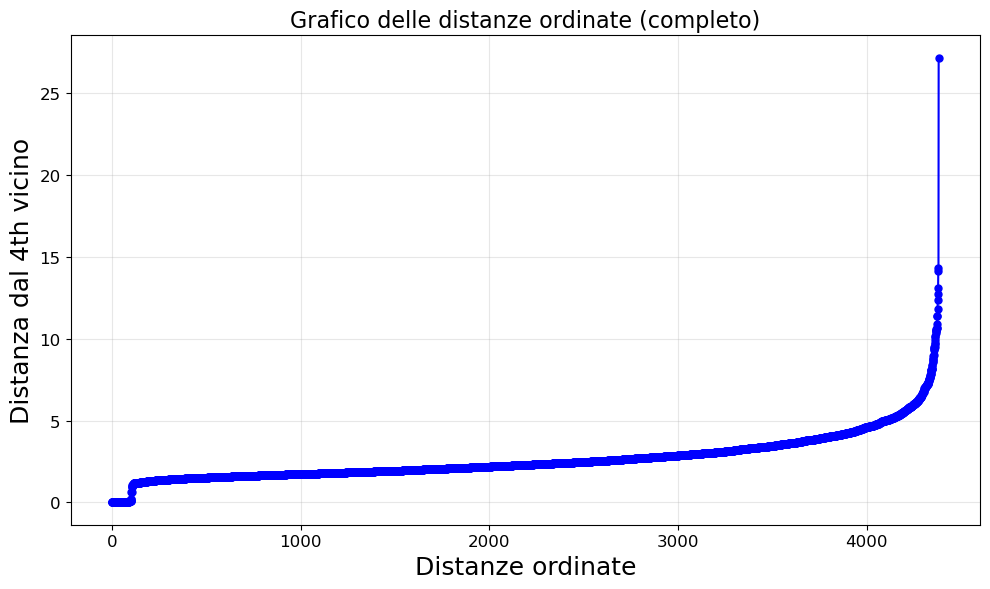

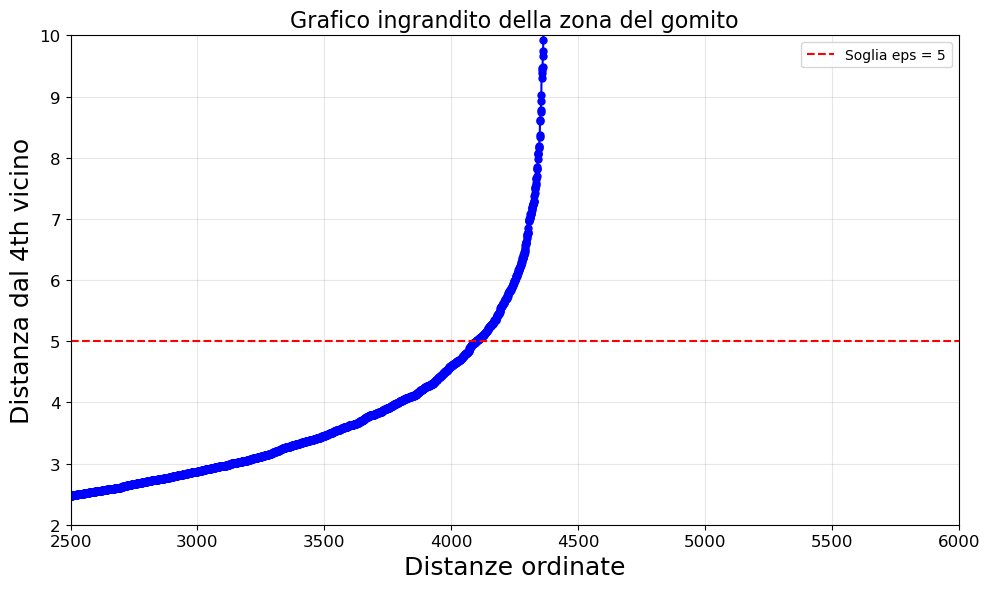

In [204]:
# Plot completo delle distanze ordinate
plt.figure(figsize=(10, 6))
plt.plot(range(0, len(kth_distances)), sorted(kth_distances), color='blue', linestyle='-', marker='o', markersize=5)
plt.ylabel('Distanza dal %sth vicino' % k, fontsize=18)
plt.xlabel('Distanze ordinate', fontsize=18)
plt.tick_params(axis='both', which='major', labelsize=12)
plt.title("Grafico delle distanze ordinate (completo)", fontsize=16)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot ingrandito della zona del gomito
plt.figure(figsize=(10, 6))
plt.plot(range(0, len(kth_distances)), sorted(kth_distances), color='blue', linestyle='-', marker='o', markersize=5)
plt.xlim(2500, 6000)  # Limita l'asse X per concentrarti sui primi punti
plt.ylim(2, 10)  # Limita l'asse Y per concentrarti sulla zona del gomito
plt.ylabel('Distanza dal %sth vicino' % k, fontsize=18)
plt.xlabel('Distanze ordinate', fontsize=18)
plt.tick_params(axis='both', which='major', labelsize=12)
plt.axhline(y=best_eps, color='red', linestyle='--', label=f'Soglia eps = {best_eps}')
plt.title("Grafico ingrandito della zona del gomito", fontsize=16)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [205]:
# Raffina la ricerca di eps attorno al valore migliore trovato
for eps_ in np.arange(3,6.1,0.1):
    eps_ = round(eps_, 2)  # Arrotonda a 2 decimali per evitare errori floating point
    dbscan = DBSCAN(eps=eps_, min_samples=best_ms)
    dbscan.fit(X)
    np.unique(dbscan.labels_, return_counts=True)
    clusters = len(np.unique(dbscan.labels_))
    
    if clusters > 1:
        silhouette = silhouette_score(X, dbscan.labels_)
        davies_bouldin = davies_bouldin_score(X, dbscan.labels_)
        print('minsample = %s, eps= %s => K= %s, Silhouette %s, Davies-Bouldin %s' % 
              (best_ms, eps_, clusters, silhouette, davies_bouldin))
        
        # Aggiorna best_eps se troviamo un silhouette migliore
        if silhouette > best_silhouette:
            best_silhouette = silhouette
            best_eps = eps_
            best_ms = best_ms
    else:
        print('minsample = %s, eps= %s => K= %s, Silhouette N/A (solo 1 cluster)' % (best_ms, eps_, clusters))

print(f'\n=== Parametri finali migliori ===')
print(f'Best min_samples: {best_ms}')
print(f'Best eps: {best_eps}')
print(f'Best Silhouette Score: {best_silhouette:}')

minsample = 9, eps= 3.0 => K= 4, Silhouette 0.13450408676274062, Davies-Bouldin 2.129879461557481
minsample = 9, eps= 3.1 => K= 4, Silhouette 0.1449053925982153, Davies-Bouldin 2.147267811520833
minsample = 9, eps= 3.2 => K= 4, Silhouette 0.16006356489054413, Davies-Bouldin 2.157998518655769
minsample = 9, eps= 3.3 => K= 3, Silhouette 0.3005610979985371, Davies-Bouldin 2.138291429971194
minsample = 9, eps= 3.4 => K= 3, Silhouette 0.3058424977143199, Davies-Bouldin 2.1420664540009864
minsample = 9, eps= 3.5 => K= 3, Silhouette 0.3086603437826286, Davies-Bouldin 2.1505650055993253
minsample = 9, eps= 3.6 => K= 3, Silhouette 0.312431989754704, Davies-Bouldin 2.1438470598509576
minsample = 9, eps= 3.7 => K= 3, Silhouette 0.320568577464539, Davies-Bouldin 2.1577410192258206
minsample = 9, eps= 3.8 => K= 3, Silhouette 0.3241467216975462, Davies-Bouldin 2.149977907311621
minsample = 9, eps= 3.9 => K= 3, Silhouette 0.3250260064854226, Davies-Bouldin 2.139715159336811
minsample = 9, eps= 4.0 =>

### la silhuette migliore è risulta con k=2 , che dividono bene in un cluster con la maggior parte della popolazione e i noise che sono i casi clinici più gravi
### provando con altri eps (eps=5) aggiungo piu cluster ma il terzo che si viene creare non rappresenta un gruppo clinicamnte distinto.

In [206]:

dbscan = DBSCAN(eps= best_eps,min_samples= best_ms)
dbscan.fit(X)

,eps,np.float64(6.0)
,min_samples,9
,metric,'euclidean'
,metric_params,None
,algorithm,'auto'
,leaf_size,30
,p,None
,n_jobs,None


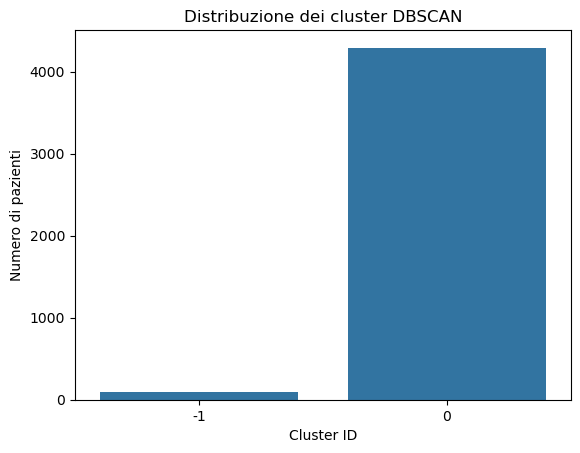

In [207]:
# Aggiungi i cluster assegnati al DataFrame
profile_df['cluster'] = dbscan.labels_

# Ora puoi creare il grafico
sns.countplot(x='cluster', data=profile_df)
plt.title("Distribuzione dei cluster DBSCAN")
plt.xlabel("Cluster ID")
plt.ylabel("Numero di pazienti")
plt.show()

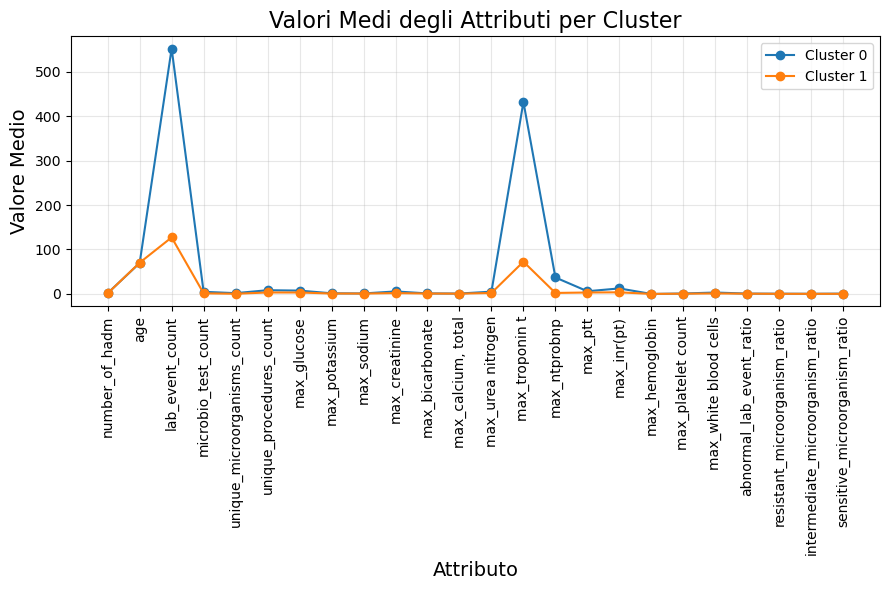

In [208]:
# Aggiungi 1 ai cluster per evitare valori negativi (noise diventa 0)
profile_df["cluster"] = dbscan.labels_ + 1

# Calcola le medie per cluster, escludendo subject_id
numeric_cols_for_plot = [col for col in numeric_cols if col not in ['subject_id', 'cluster']]
means = profile_df.groupby('cluster')[numeric_cols_for_plot].mean()

# Crea un grafico a linee per ciascun cluster
plt.figure(figsize=(9, 6))
for cluster in means.index:
    plt.plot(means.columns, means.loc[cluster], marker='o', label=f'Cluster {cluster}')

plt.xlabel('Attributo', fontsize=14)
plt.ylabel('Valore Medio', fontsize=14)
plt.title('Valori Medi degli Attributi per Cluster', fontsize=16)
plt.legend()
plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

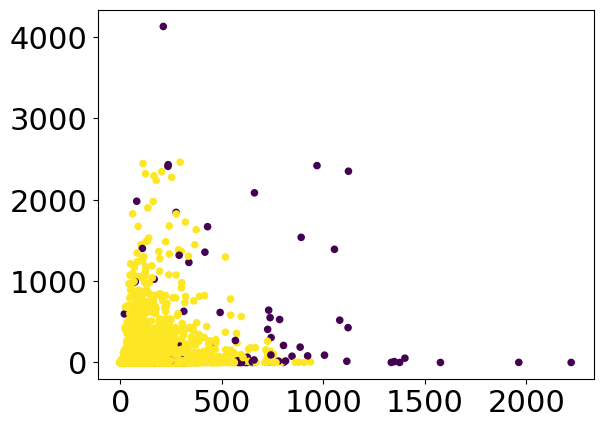

In [209]:


# Ora puoi creare il grafico
plt.scatter(profile_df['lab_event_count'], profile_df['max_troponin t'], c=dbscan.labels_, s=20)
plt.tick_params(axis='both', which='major', labelsize=22)
plt.show()

# Analisi Approfondita dei Cluster

Analizziamo i cluster creati con DBSCAN per comprendere le caratteristiche dei diversi gruppi di pazienti.

In [210]:
# 1. Statistiche generali sui cluster
print("=" * 60)
print("STATISTICHE GENERALI SUI CLUSTER")
print("=" * 60)

# Conta i pazienti per cluster
cluster_counts = profile_df['cluster'].value_counts().sort_index()
print(f"\nNumero totale di pazienti: {len(profile_df)}")
print(f"Numero di cluster (incluso noise): {len(cluster_counts)}")
print("\nDistribuzione pazienti per cluster:")
for cluster_id, count in cluster_counts.items():
    percentage = (count / len(profile_df)) * 100
    cluster_name = "Noise" if cluster_id == 0 else f"Cluster {cluster_id}"
    print(f"  {cluster_name}: {count} pazienti ({percentage:.2f}%)")



STATISTICHE GENERALI SUI CLUSTER

Numero totale di pazienti: 4383
Numero di cluster (incluso noise): 2

Distribuzione pazienti per cluster:
  Noise: 91 pazienti (2.08%)
  Cluster 1: 4292 pazienti (97.92%)


## Heatmap - Confronto Visivo tra Cluster

La heatmap mostra i **valori medi** di ogni feature numerica per ciascun cluster:
- **Colori caldi (rosso)**: valori alti
- **Colori freddi (blu)**: valori bassi
- **Righe**: features 
- **Colonne**: cluster

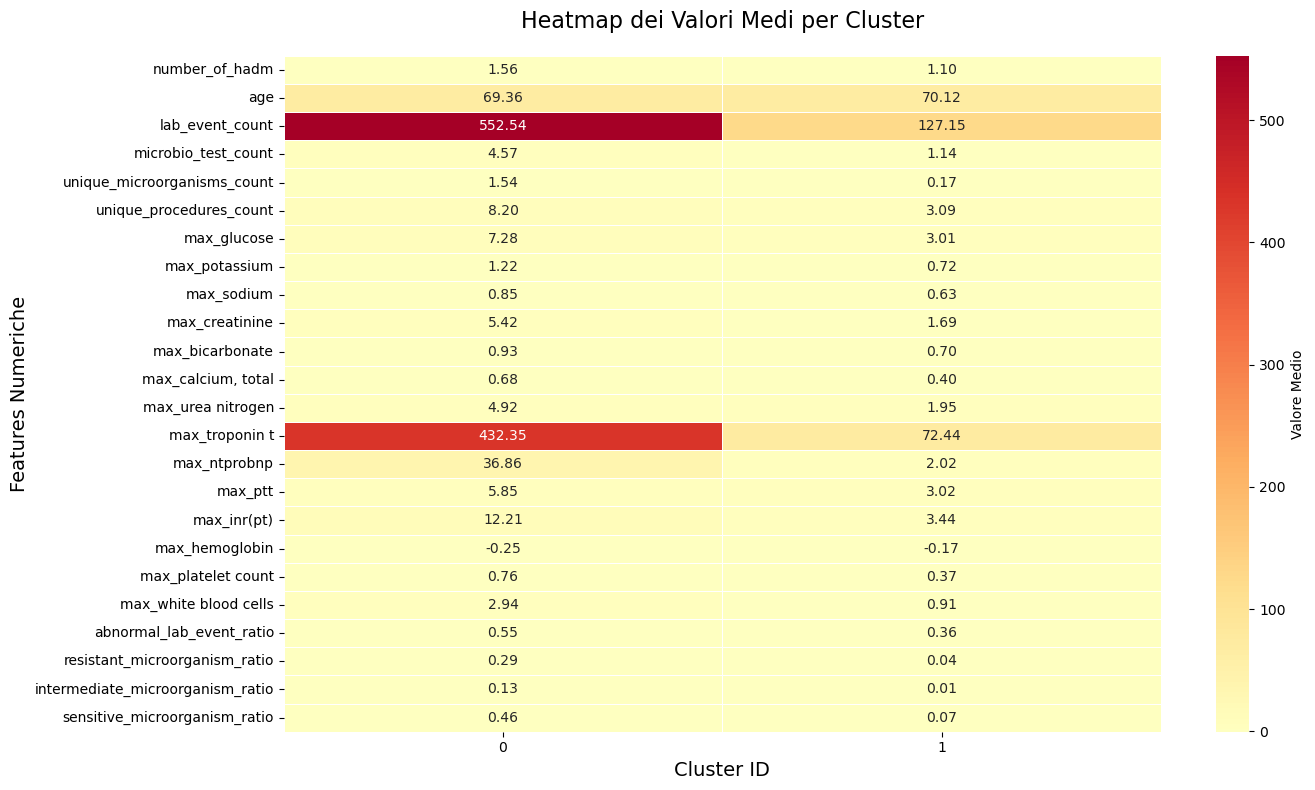

In [211]:
# Calcola le medie per cluster (escludendo subject_id e cluster)
numeric_cols_analysis = [col for col in numeric_cols if col not in ['subject_id', 'cluster']]
cluster_means = profile_df.groupby('cluster')[numeric_cols_analysis].mean()

# Crea la heatmap
plt.figure(figsize=(14, 8))
sns.heatmap(cluster_means.T, annot=True, fmt='.2f', cmap='RdYlBu_r', 
            cbar_kws={'label': 'Valore Medio'}, linewidths=0.5, center=0.5)
plt.title('Heatmap dei Valori Medi per Cluster', fontsize=16, pad=20)
plt.xlabel('Cluster ID', fontsize=14)
plt.ylabel('Features Numeriche', fontsize=14)
plt.tight_layout()
plt.show()

## Come Interpretare l'Heatmap

### Lettura Base
- **Ogni colonna** rappresenta un cluster diverso (es: -1 = noise, 0 = cluster 1, ecc.)
- **Ogni riga** rappresenta una feature numerica (età, troponina, lab_event_count, ecc.)
- **I numeri** nelle celle mostrano il valore medio di quella feature in quel cluster
- **I colori** aiutano la visualizzazione:
  - 🔴 **Rosso/Arancione**: valori alti rispetto agli altri cluster
  - 🔵 **Blu**: valori bassi rispetto agli altri cluster
  - ⚪ **Bianco/Giallo**: valori medi

### Come Confrontare i Cluster

1. **Confronto orizzontale** (lungo una riga):
   - Guarda una singola feature attraverso tutti i cluster
   -se una feature e rossa in un cluster e gialla negli altri, vuol dire che quel cluster ha valori critici
2. **Confronto verticale** (lungo una colonna):
   - Guarda il profilo completo di un singolo cluster
   - Esempio: se una colonna ha molte righe rosse, quel cluster ha pazienti con valori generalmente elevati

3. **Pattern distintivi**:
   - **Cluster simili**: avranno pattern di colori simili
   - **Cluster distinti**: avranno pattern molto diversi
   - **Features discriminanti**: righe con forte contrasto di colore tra cluster

### Esempio di Interpretazione Clinica

Si nota  che il **cluster del noise** (-1) ha:
- `max_troponin t` **alto** (rosso) → danno cardiaco elevato
- `max_ntprobnp` **alto** (rosso) → insufficienza cardiaca grave  
- `lab_event_count` **alto** (rosso) → molte analisi = pazienti complessi


**Conclusione**: Il noise potrebbe rappresentare **pazienti critici ad alto rischio** che non rientrano nei pattern standard.

In [212]:
#save the column cluster in  the profile
labels = dbscan.labels_
profile_df['cluster'] = labels
profile_df


,subject_id,ACS_acute_ischemic,Chronic_ischemic,Heart_failure,Valvular_nonrheumatic,Myocarditis_or_cardiomyopathy,Pericardial_disease,Endocarditis,Cardiac_arrest,Arrhythmias_or_conduction,...,max_ptt,max_inr(pt),max_hemoglobin,max_platelet count,max_white blood cells,abnormal_lab_event_ratio,resistant_microorganism_ratio,intermediate_microorganism_ratio,sensitive_microorganism_ratio,cluster
0,10000980,1,0,1,0,0,0,0,0,0,...,5.286957,2.0,-0.475000,0.251724,0.328571,0.410714,0.0,0.0,0.0,0
1,10002013,1,0,0,0,0,0,0,0,0,...,4.634783,0.5,0.025000,0.389655,0.714286,0.375000,0.0,0.0,0.0,0
2,10002155,1,0,0,0,0,0,0,0,0,...,5.661538,10.5,0.125000,0.341379,0.500000,0.384058,0.0,0.0,0.0,0
3,10004457,0,0,0,1,0,0,0,0,0,...,0.000000,0.0,-0.075000,0.396552,0.357143,0.300000,0.0,0.0,0.0,0
4,10007058,1,0,0,0,0,0,0,0,0,...,4.582609,1.5,-0.315789,0.220000,1.416667,0.375000,0.0,0.0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4378,19998596,0,0,0,0,0,0,0,0,1,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0
4379,19998597,0,0,0,0,0,1,0,0,0,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0
4380,19998598,0,0,0,0,0,0,0,0,1,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0
4381,19998599,0,0,0,0,0,1,0,0,0,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0


In [213]:
#percentage of each desease in each cluster
disease_cols = ['ACS_acute_ischemic','Chronic_ischemic','Heart_failure','Valvular_nonrheumatic','Myocarditis_or_cardiomyopathy','Pericardial_disease','Endocarditis','Cardiac_arrest','Arrhythmias_or_conduction']
disease_summary = profile_df.groupby('cluster')[disease_cols].mean() * 100  
disease_summary

,ACS_acute_ischemic,Chronic_ischemic,Heart_failure,Valvular_nonrheumatic,Myocarditis_or_cardiomyopathy,Pericardial_disease,Endocarditis,Cardiac_arrest,Arrhythmias_or_conduction
cluster,,,,,,,,,
-1,41.758242,5.494505,48.351648,6.593407,1.098901,3.296703,0.000000,0.000000,10.989011
0,32.409133,14.561976,29.147251,6.127679,1.118360,5.288910,0.885368,0.046598,15.051258


### non riuscuiamo ad individuare una distinzione delle patalogie

In [214]:
#  valori della troponina in ogni cluster
troponin_summary = profile_df.groupby('cluster')['max_troponin t'].describe()
troponin_summary

,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
-1,91.0,432.351648,775.973000,0.0,7.0,38.0,524.0,4130.0
0,4292.0,72.440587,210.714157,0.0,0.0,2.0,34.0,2462.0


In [215]:
#valori del nt-proBNP in ogni cluster
nt_summary = profile_df.groupby('cluster')['max_ntprobnp'].describe()
nt_summary

,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
-1,91.0,36.862192,80.690695,0.0,0.0,0.0,24.334133,407.881720
0,4292.0,2.020427,8.937978,0.0,0.0,0.0,0.000000,136.056769


In [216]:
#valore del inr_ptt in ogni cluster
pt_summary = profile_df.groupby('cluster')['max_inr(pt)'].describe()
pt_summary

,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
-1,91.0,12.208791,18.416036,0.0,2.0,4.5,15.75,109.5
0,4292.0,3.441577,5.206885,-0.5,0.5,1.5,3.50,62.0


### i valore della troponina  e della nt-proBNP nel cluster NOISE è decidamente più elevato: casi clinici più gravi

In [217]:
# lab events count  per cluster
lab_events_summary = profile_df.groupby('cluster')['lab_event_count'].describe()
lab_events_summary

,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
-1,91.0,552.538462,435.695569,20.0,213.0,453.0,761.0,2221.0
0,4292.0,127.147950,113.235309,0.0,53.0,92.0,165.0,937.0


### nel cluster del noise ci sono i pazienti con più osservazioni: clinicamnte piu gravi

In [218]:
#distribution of age in each cluster
age_summary = profile_df.groupby('cluster')['age'].describe()
age_summary

,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
-1,91.0,69.357143,10.712735,25.0,69.0,71.0,75.0,91.0
0,4292.0,70.122903,9.412966,18.0,66.0,69.0,75.0,95.0


## Visualizzazioni Avanzate dei Cluster

Creiamo grafici più dettagliati per distinguere meglio i cluster.

### 1. Boxplot - Confronto Features Chiave tra Cluster

I boxplot mostrano la distribuzione completa (mediana, quartili, outlier) di ogni feature per cluster.

C:\Users\Cominotti\AppData\Local\Temp\ipykernel_21568\2428424271.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=profile_df, x='cluster', y=feature, ax=axes[idx], palette='Set2')
C:\Users\Cominotti\AppData\Local\Temp\ipykernel_21568\2428424271.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=profile_df, x='cluster', y=feature, ax=axes[idx], palette='Set2')
C:\Users\Cominotti\AppData\Local\Temp\ipykernel_21568\2428424271.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=profile_df, x='cluster', y=feature, ax=axes[idx],

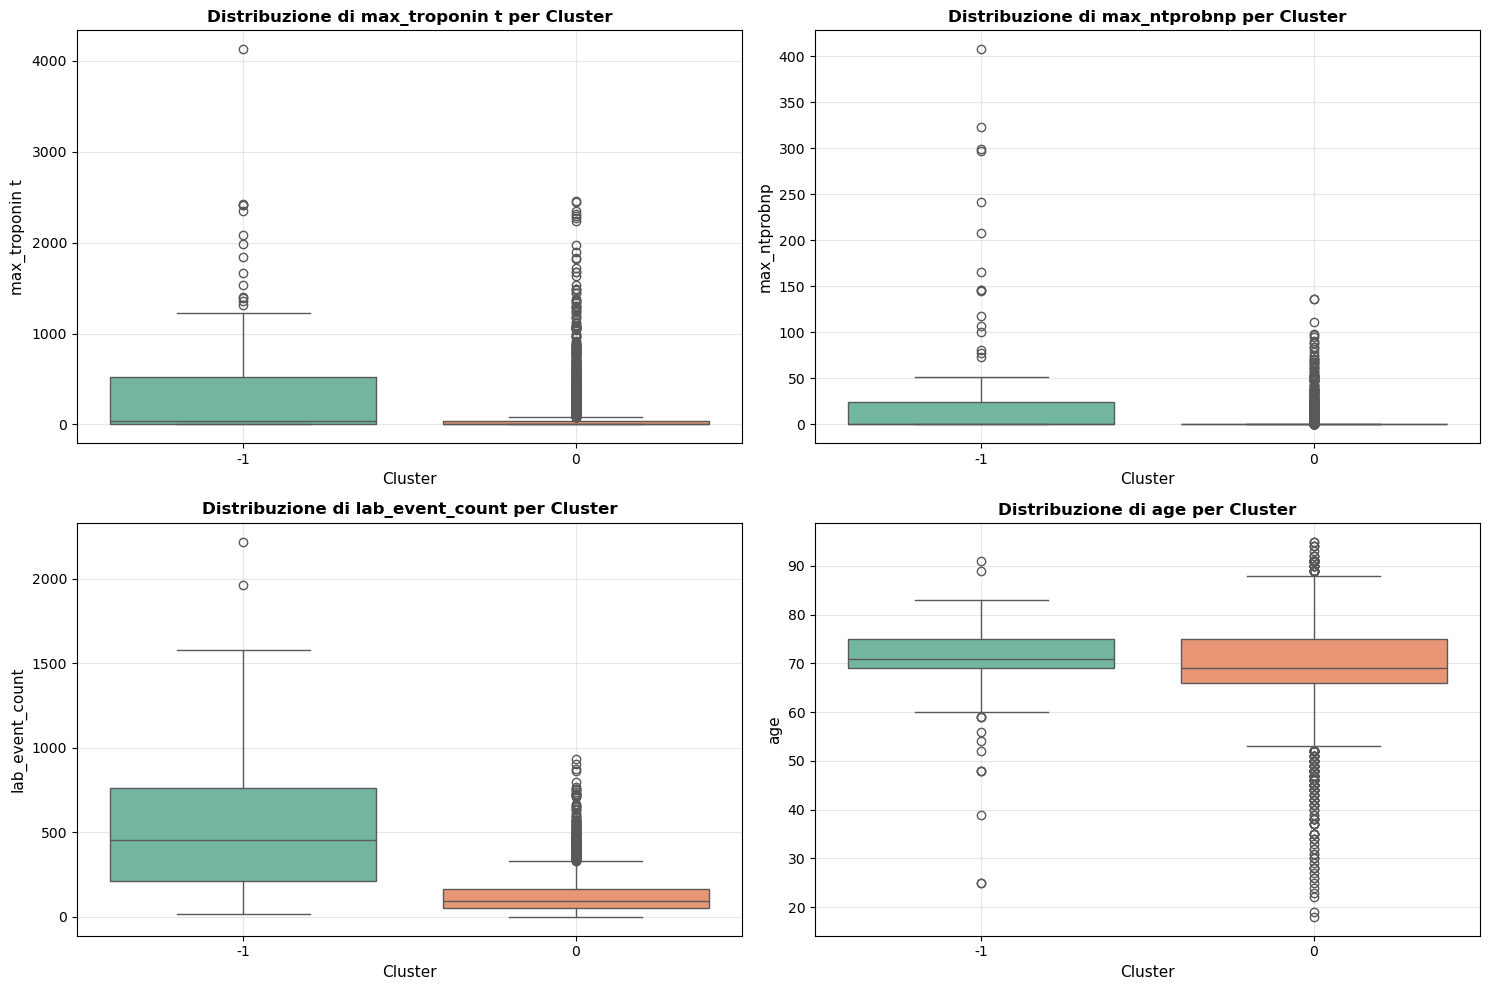

In [219]:
# Seleziona features chiave da visualizzare
key_features = ['max_troponin t', 'max_ntprobnp', 'lab_event_count', 'age']

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for idx, feature in enumerate(key_features):
    sns.boxplot(data=profile_df, x='cluster', y=feature, ax=axes[idx], palette='Set2')
    axes[idx].set_title(f'Distribuzione di {feature} per Cluster', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Cluster', fontsize=11)
    axes[idx].set_ylabel(feature, fontsize=11)
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 5. Radar Chart - Profilo Cluster

Mostra il profilo medio di ogni cluster su tutte le features normalizzate.

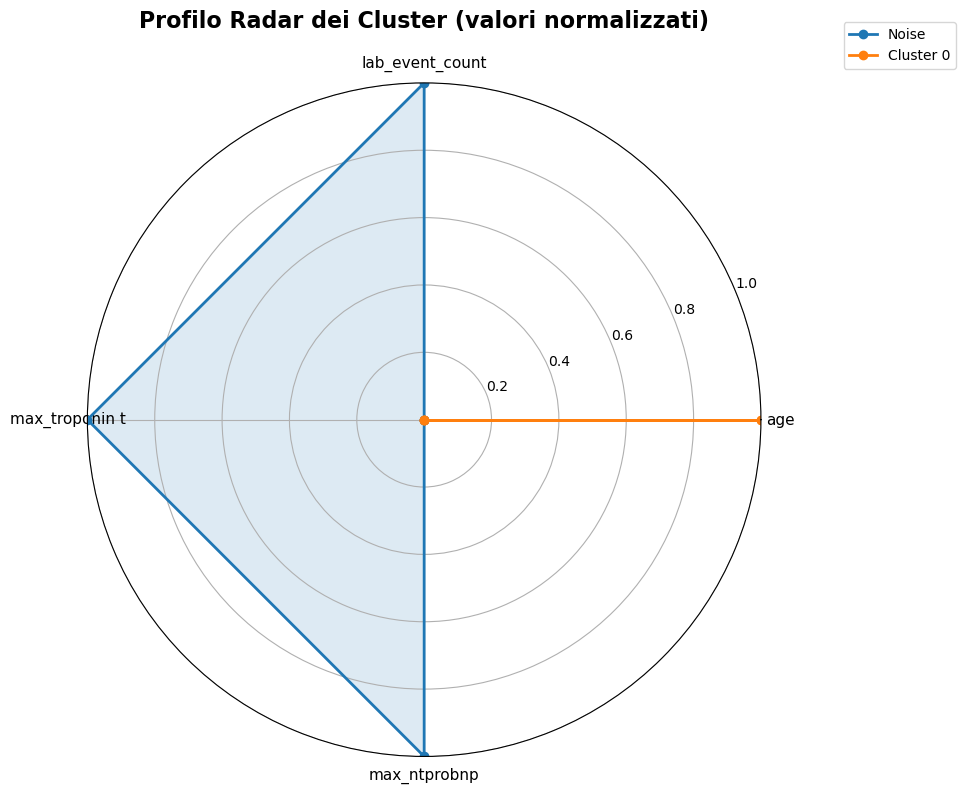

In [220]:
import math

# Calcola le medie per cluster (normalizzate 0-1)
features_radar = ['age', 'lab_event_count', 'max_troponin t', 'max_ntprobnp']
cluster_radar = profile_df.groupby('cluster')[features_radar].mean()

# Normalizza tra 0 e 1
from sklearn.preprocessing import MinMaxScaler
scaler_radar = MinMaxScaler()
cluster_radar_norm = pd.DataFrame(
    scaler_radar.fit_transform(cluster_radar),
    columns=cluster_radar.columns,
    index=cluster_radar.index
)

# Crea radar chart
num_vars = len(features_radar)
angles = [n / float(num_vars) * 2 * math.pi for n in range(num_vars)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(projection='polar'))

for cluster_id in cluster_radar_norm.index:
    values = cluster_radar_norm.loc[cluster_id].values.tolist()
    values += values[:1]
    label = f'Noise' if cluster_id == -1 else f'Cluster {cluster_id}'
    ax.plot(angles, values, 'o-', linewidth=2, label=label)
    ax.fill(angles, values, alpha=0.15)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(features_radar, size=11)
ax.set_ylim(0, 1)
ax.set_title('Profilo Radar dei Cluster (valori normalizzati)', size=16, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
ax.grid(True)
plt.tight_layout()
plt.show()

### 6. Scatter Plot - Separazione dei Cluster per Coppie di Features

Visualizziamo come i cluster si separano su diverse combinazioni di features.

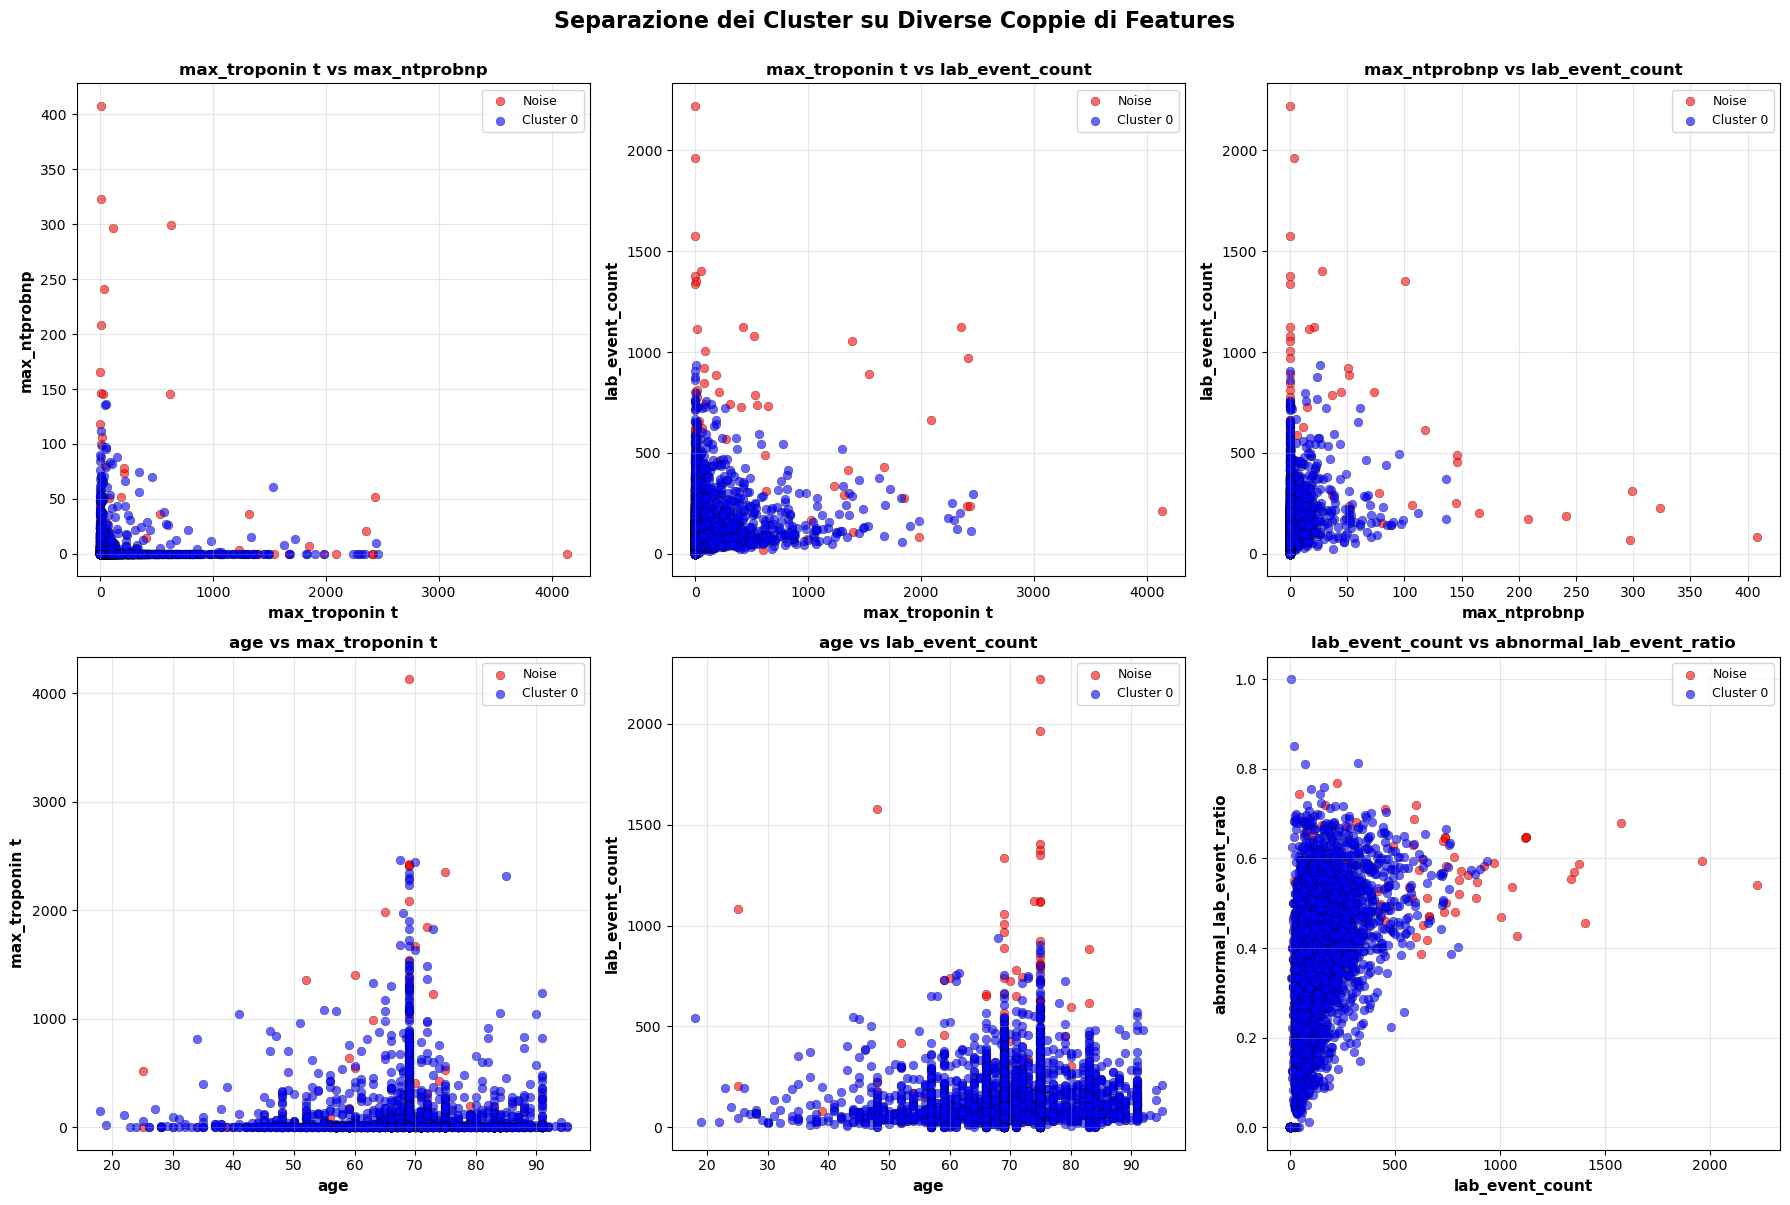

In [221]:
# Scatter plot con diverse combinazioni di features
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

# Definisci le coppie di features da visualizzare
feature_pairs = [
    ('max_troponin t', 'max_ntprobnp'),
    ('max_troponin t', 'lab_event_count'),
    ('max_ntprobnp', 'lab_event_count'),
    ('age', 'max_troponin t'),
    ('age', 'lab_event_count'),
    ('lab_event_count', 'abnormal_lab_event_ratio')
]

# Mappa colori per cluster
colors_map = {-1: 'red', 0: 'blue', 1: 'green', 2: 'orange', 3: 'purple'}

for idx, (feat_x, feat_y) in enumerate(feature_pairs):
    for cluster_id in sorted(profile_df['cluster'].unique()):
        cluster_data = profile_df[profile_df['cluster'] == cluster_id]
        label = f'Noise' if cluster_id == -1 else f'Cluster {cluster_id}'
        color = colors_map.get(cluster_id, 'gray')
        
        axes[idx].scatter(cluster_data[feat_x], cluster_data[feat_y],
                         label=label, alpha=0.6, s=40, c=color, edgecolors='k', linewidth=0.3)
    
    axes[idx].set_xlabel(feat_x, fontsize=11, fontweight='bold')
    axes[idx].set_ylabel(feat_y, fontsize=11, fontweight='bold')
    axes[idx].set_title(f'{feat_x} vs {feat_y}', fontsize=12, fontweight='bold')
    axes[idx].legend(fontsize=9, loc='best')
    axes[idx].grid(True, alpha=0.3)

plt.suptitle('Separazione dei Cluster su Diverse Coppie di Features', fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

### 7. Scatter 3D - Visualizzazione Tridimensionale

Visualizzazione 3D con le tre features più importanti per vedere la separazione nello spazio.

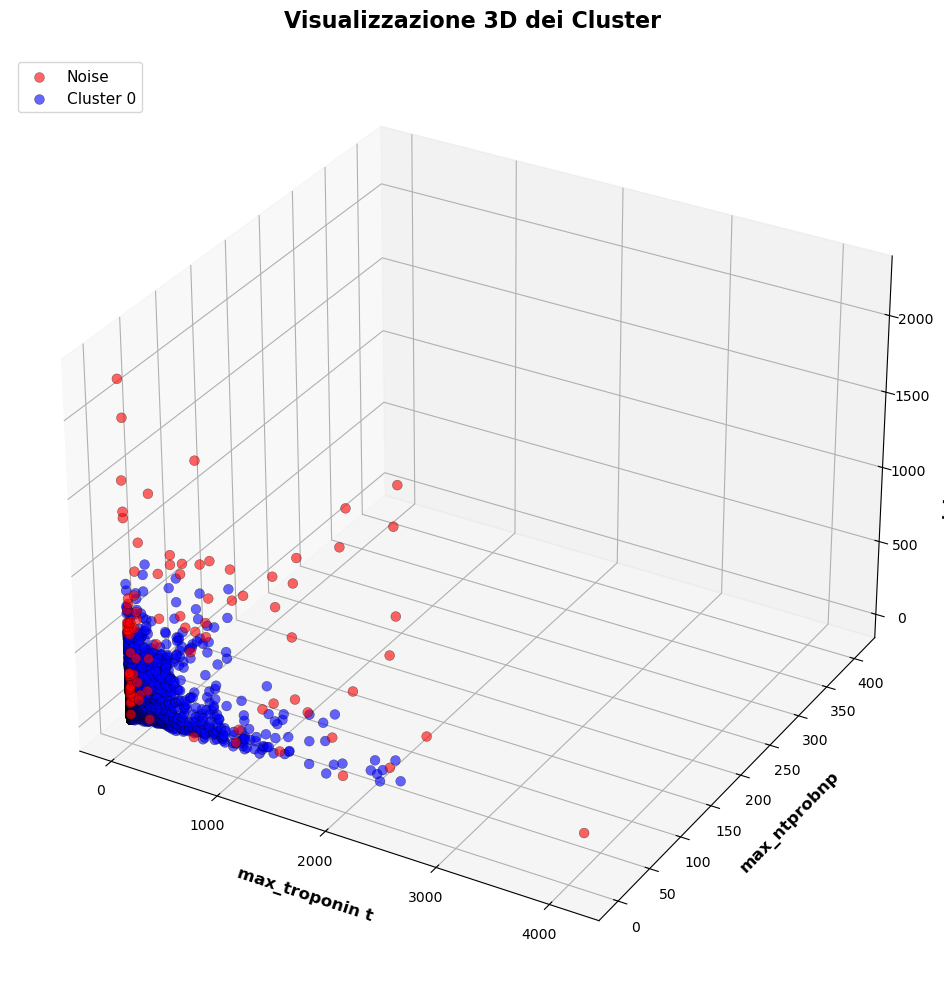

In [222]:
from mpl_toolkits.mplot3d import Axes3D

# Crea scatter 3D con le tre features più importanti
fig = plt.figure(figsize=(14, 10))
ax = fig.add_subplot(111, projection='3d')

# Features da visualizzare
feat_x = 'max_troponin t'
feat_y = 'max_ntprobnp'
feat_z = 'lab_event_count'

for cluster_id in sorted(profile_df['cluster'].unique()):
    cluster_data = profile_df[profile_df['cluster'] == cluster_id]
    label = f'Noise' if cluster_id == -1 else f'Cluster {cluster_id}'
    color = colors_map.get(cluster_id, 'gray')
    
    ax.scatter(cluster_data[feat_x], 
               cluster_data[feat_y], 
               cluster_data[feat_z],
               label=label, alpha=0.6, s=50, c=color, edgecolors='k', linewidth=0.3)

ax.set_xlabel(feat_x, fontsize=12, fontweight='bold', labelpad=10)
ax.set_ylabel(feat_y, fontsize=12, fontweight='bold', labelpad=10)
ax.set_zlabel(feat_z, fontsize=12, fontweight='bold', labelpad=10)
ax.set_title('Visualizzazione 3D dei Cluster', fontsize=16, fontweight='bold', pad=20)
ax.legend(fontsize=11, loc='upper left')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Interpretazione degli Scatter Plot

**Cosa cercare:**
- 🎯 **Cluster ben separati**: punti dello stesso colore raggruppati, colori diversi distanti
- ⚠️ **Overlap**: punti di colori diversi mescolati = difficile distinzione su quelle features
- 🔍 **Outlier del noise** (rosso): spesso sparsi o in zone estreme del grafico
- 📊 **Features discriminanti**: se un grafico mostra buona separazione, quelle features distinguono bene i cluster

**Per il tuo caso:**
- Se troponina vs NT-proBNP separa bene → marcatori cardiaci distinguono i gruppi
- Se lab_event_count separa → frequenza osservazioni è discriminante
- Se vedi noise sparso → pazienti atipici che non seguono pattern comuni